<a href="https://colab.research.google.com/github/abrarjahinzihan/House_Price_Prediction/blob/main/House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# House Price Prediction (King County, USA)

**Goal:** Predict residential property prices accurately using a multi-dimensional housing dataset, helping buyers make informed decisions and enabling automated valuation for real-estate businesses.

**Requirements covered in this notebook**
1. Multi-dimensional features: **zip code / location**, **square footage**, **bedrooms / bathrooms**, **amenities** (waterfront, view, grade, condition, basement) and **property age**
2. **Log transformation** of the skewed price target
3. **Outlier handling** (data-entry errors, target outliers, winsorizing)
4. **Benchmark Gradient Boosting (GBR) vs XGBoost** against Linear/Ridge and Random Forest baselines
5. Hyper-parameter tuning, evaluation (RMSE, MAE, R², MAPE), feature importance, and a reusable prediction function

**Reference:** *Housing Prices – Advanced Regression Techniques* guide (Kaggle).

## 1. Setup & Load Data (Google Drive)

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# ---- Mount Google Drive (Colab) ----
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - skipping drive mount')



Mounted at /content/drive


In [ ]:

DATA_PATH = '/content/drive/MyDrive/Untitled Folder 2/kc_house_data.csv'
DATA_PATH = os.environ.get('DATA_PATH', DATA_PATH)

df_raw = pd.read_csv(DATA_PATH)
print('Shape:', df_raw.shape)
df_raw.head()

Shape: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

try:
    from xgboost import XGBRegressor
except ImportError:
    raise ImportError('Run: !pip install xgboost')

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

## 2. Data Understanding

In [ ]:
df_raw.info()
print('\nMissing values:', df_raw.isna().sum().sum())
print('Duplicate ids:', df_raw['id'].duplicated().sum())
df_raw.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


### 2.1 Target distribution – why a log transform?

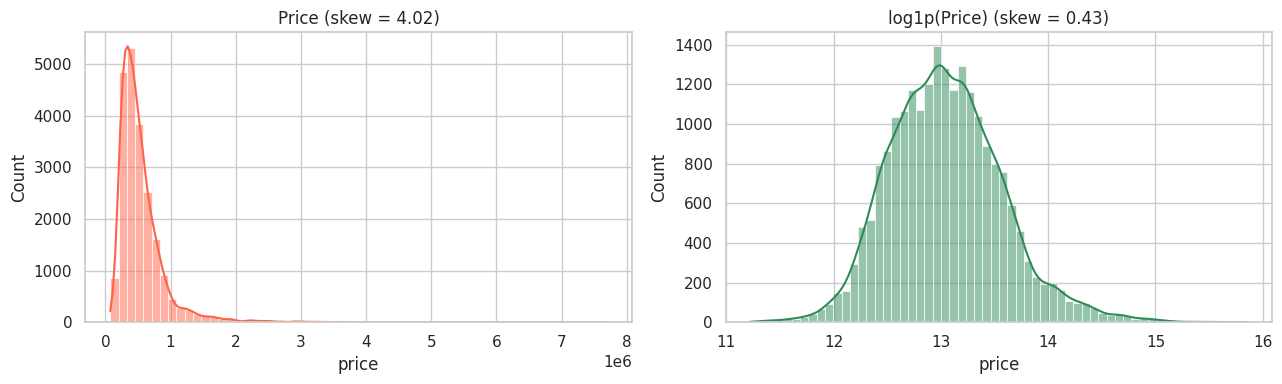

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_raw['price'], bins=60, kde=True, ax=ax[0], color='tomato')
ax[0].set_title(f"Price (skew = {df_raw['price'].skew():.2f})")
sns.histplot(np.log1p(df_raw['price']), bins=60, kde=True, ax=ax[1], color='seagreen')
ax[1].set_title(f"log1p(Price) (skew = {np.log1p(df_raw['price']).skew():.2f})")
plt.tight_layout(); plt.show()

Price is **heavily right-skewed**. Training on `log1p(price)` makes the target close to normal, stabilises variance, and makes errors proportional (a $50k miss matters more on a $200k house than on a $2M one). Predictions are converted back with `expm1`.

### 2.2 Key relationships

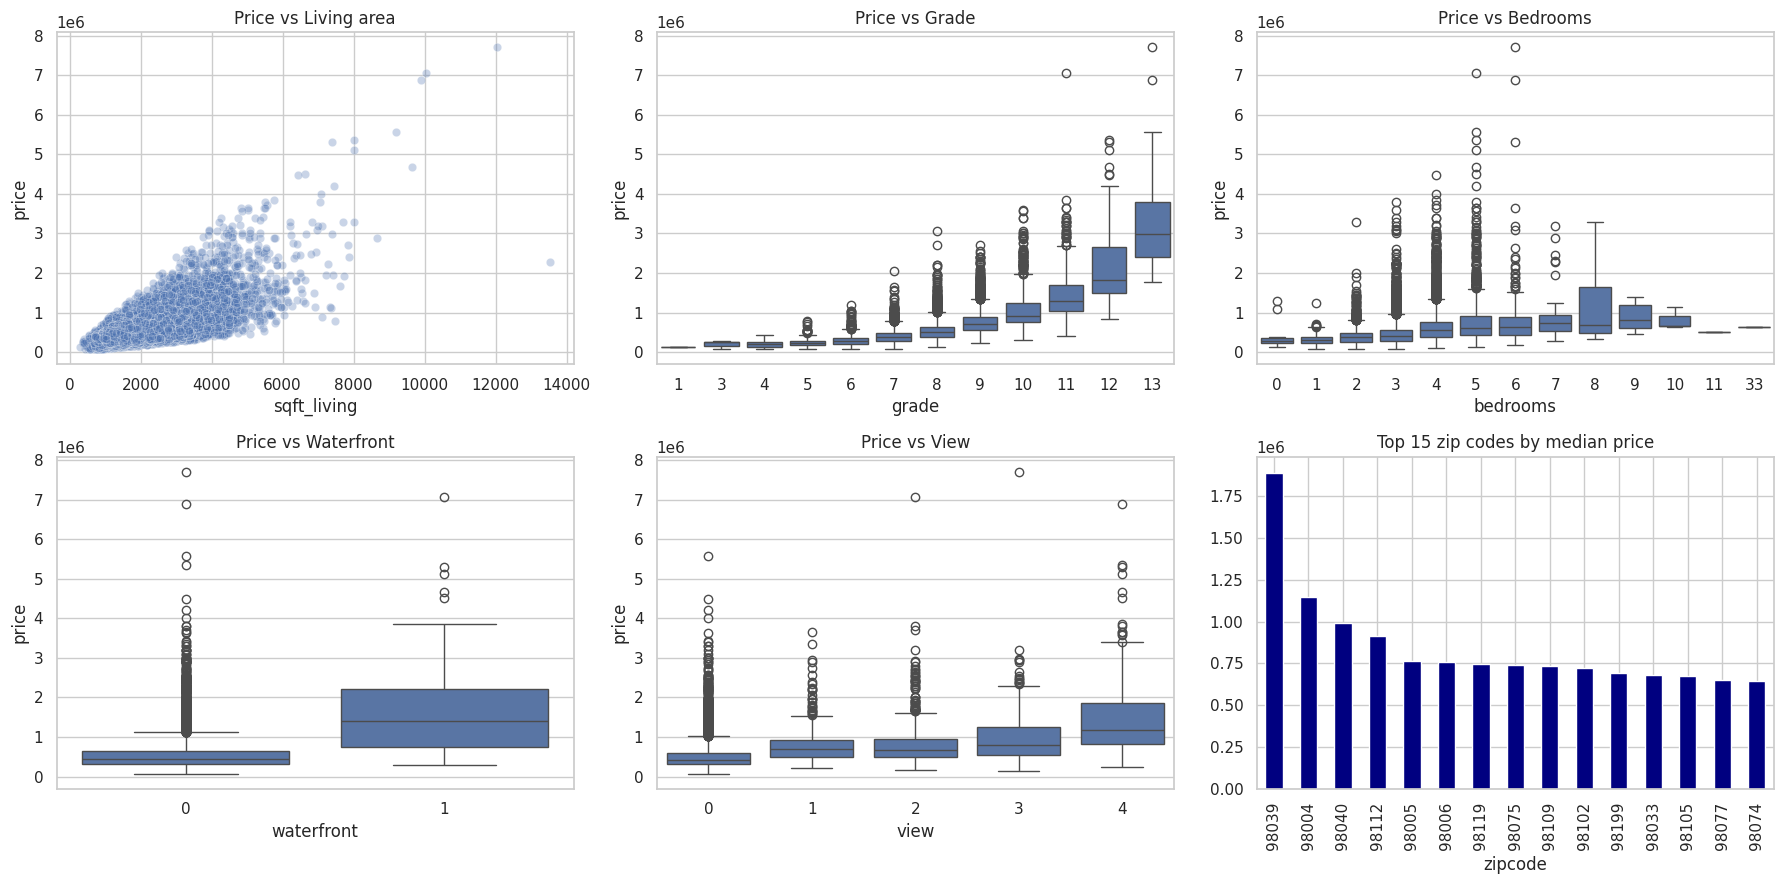

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
sns.scatterplot(data=df_raw, x='sqft_living', y='price', alpha=.3, ax=ax[0, 0])
ax[0, 0].set_title('Price vs Living area')
sns.boxplot(data=df_raw, x='grade', y='price', ax=ax[0, 1]); ax[0, 1].set_title('Price vs Grade')
sns.boxplot(data=df_raw, x='bedrooms', y='price', ax=ax[0, 2]); ax[0, 2].set_title('Price vs Bedrooms')
sns.boxplot(data=df_raw, x='waterfront', y='price', ax=ax[1, 0]); ax[1, 0].set_title('Price vs Waterfront')
sns.boxplot(data=df_raw, x='view', y='price', ax=ax[1, 1]); ax[1, 1].set_title('Price vs View')
zip_med = df_raw.groupby('zipcode')['price'].median().sort_values(ascending=False)
zip_med.head(15).plot(kind='bar', ax=ax[1, 2], color='navy'); ax[1, 2].set_title('Top 15 zip codes by median price')
plt.tight_layout(); plt.show()

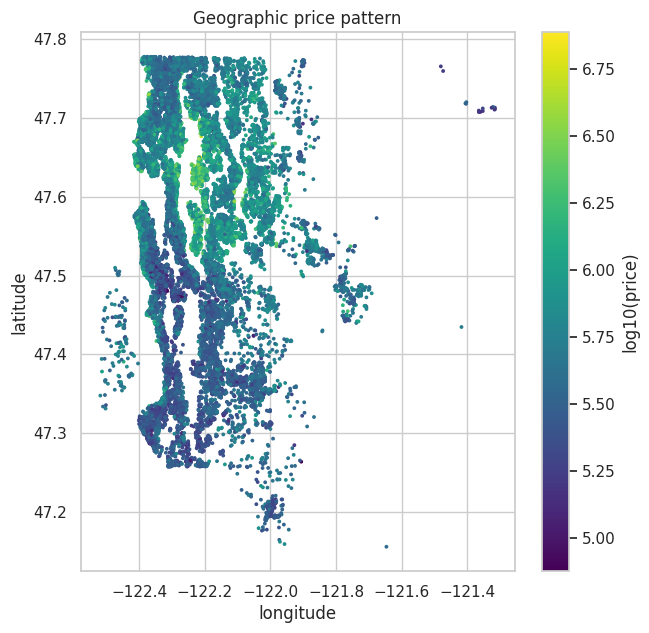

price            1.000
sqft_living      0.702
grade            0.667
sqft_above       0.606
sqft_living15    0.585
bathrooms        0.525
view             0.397
sqft_basement    0.324
bedrooms         0.308
lat              0.307
waterfront       0.266
floors           0.257
yr_renovated     0.126
sqft_lot         0.090
sqft_lot15       0.082
yr_built         0.054
condition        0.036
long             0.022
zipcode         -0.053
Name: price, dtype: float64


In [ ]:
plt.figure(figsize=(7, 7))
sc = plt.scatter(df_raw['long'], df_raw['lat'], c=np.log10(df_raw['price']), cmap='viridis', s=3)
plt.colorbar(sc, label='log10(price)'); plt.xlabel('longitude'); plt.ylabel('latitude')
plt.title('Geographic price pattern'); plt.show()

corr = df_raw.drop(columns=['id', 'date']).corr()['price'].sort_values(ascending=False)
print(corr.round(3))

## 3. Cleaning & Outlier Handling

Three levels of outlier treatment:
1. **Data-entry errors** (removed before split): e.g. a 33-bedroom house on 1,620 sqft, houses with 0 bedrooms *and* 0 bathrooms.
2. **Target outliers** (train set only): rows whose `log(price)` lies beyond 3×IQR.
3. **Feature outliers**: *winsorizing* (capping at the 0.5th / 99.5th train percentile) so extreme lots / sizes do not distort the models.

Outlier rules are **learned on the train set only** so there is no leakage into the test set.

In [ ]:
df = df_raw.copy()
n0 = len(df)

# 1) Data-entry errors / impossible records
bad = (df['bedrooms'] >= 11) | ((df['bedrooms'] == 0) & (df['bathrooms'] == 0)) | (df['sqft_living'] <= 0)
print('Removing', bad.sum(), 'invalid rows:')
print(df.loc[bad, ['bedrooms', 'bathrooms', 'sqft_living', 'price']])
df = df[~bad].reset_index(drop=True)

# Keep one record per sale (id + date)
df = df.drop_duplicates(subset=['id', 'date']).reset_index(drop=True)
print(f'Rows: {n0} -> {len(df)}')

Removing 9 invalid rows:
       bedrooms  bathrooms  sqft_living      price
875           0       0.00         3064  1095000.0
3119          0       0.00         1470   380000.0
6994          0       0.00         4810  1295650.0
8757         11       3.00         3000   520000.0
9773          0       0.00         2460   355000.0
9854          0       0.00         1470   235000.0
14423         0       0.00          844   139950.0
15870        33       1.75         1620   640000.0
19452         0       0.00          290   142000.0
Rows: 21613 -> 21604


## 4. Train / Test Split

In [ ]:
train_raw, test_raw = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
train_raw = train_raw.reset_index(drop=True)
test_raw = test_raw.reset_index(drop=True)

# 2) Target outliers (train only), on log scale
y_log_tmp = np.log1p(train_raw['price'])
q1, q3 = y_log_tmp.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 3 * iqr, q3 + 3 * iqr
mask = (y_log_tmp >= lo) & (y_log_tmp <= hi)
print(f'Train target outliers removed: {(~mask).sum()}  (price range kept: ${np.expm1(lo):,.0f} - ${np.expm1(hi):,.0f})')
train_raw = train_raw[mask].reset_index(drop=True)

y_train = np.log1p(train_raw['price'])
y_test = np.log1p(test_raw['price'])
print('Train:', train_raw.shape, ' Test:', test_raw.shape)

Train target outliers removed: 5  (price range kept: $40,594 - $5,053,267)
Train: (17278, 21)  Test: (4321, 21)


## 5. Feature Engineering

| Group | Features |
|---|---|
| **Location** | `zip_te` (out-of-fold smoothed target encoding of zip code), `lat`, `long`, `dist_downtown_km` (haversine to downtown Seattle) |
| **Size** | `sqft_living`, `sqft_lot`, `sqft_above`, `sqft_basement`, `sqft_per_room`, `lot_ratio`, neighbour-relative size |
| **Rooms** | `bedrooms`, `bathrooms`, `floors`, `total_rooms`, `bath_per_bed` |
| **Amenities** | `waterfront`, `view`, `grade`, `condition`, `has_basement`, `amenity_score` |
| **Property age** | `house_age`, `is_renovated`, `years_since_reno`, `effective_age`, `sale_year`, `sale_month` |

Zip code is a high-cardinality categorical (70 values). Instead of one-hot encoding we use a **smoothed target encoding computed out-of-fold** on the training set (and fitted on the whole train set for test/new data) to avoid target leakage.

In [ ]:
DOWNTOWN = (47.6062, -122.3321)

def haversine_km(lat, lon, lat0=DOWNTOWN[0], lon0=DOWNTOWN[1]):
    R = 6371.0
    p1, p2 = np.radians(lat), np.radians(lat0)
    dphi = p2 - p1
    dl = np.radians(lon0 - lon)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def engineer(d):
    d = d.copy()
    d['date'] = pd.to_datetime(d['date'].astype(str).str[:8], format='%Y%m%d')
    d['sale_year'] = d['date'].dt.year
    d['sale_month'] = d['date'].dt.month

    # --- property age ---
    d['house_age'] = (d['sale_year'] - d['yr_built']).clip(lower=0)
    d['is_renovated'] = (d['yr_renovated'] > 0).astype(int)
    d['years_since_reno'] = np.where(d['is_renovated'] == 1, d['sale_year'] - d['yr_renovated'], d['house_age'])
    d['years_since_reno'] = d['years_since_reno'].clip(lower=0)
    d['effective_age'] = np.minimum(d['house_age'], d['years_since_reno'])

    # --- rooms & size ---
    d['total_rooms'] = d['bedrooms'] + d['bathrooms']
    d['sqft_per_room'] = d['sqft_living'] / d['total_rooms'].clip(lower=1)
    d['bath_per_bed'] = d['bathrooms'] / d['bedrooms'].clip(lower=1)
    d['lot_ratio'] = d['sqft_living'] / d['sqft_lot']
    d['living_vs_neighbors'] = d['sqft_living'] / d['sqft_living15']
    d['lot_vs_neighbors'] = d['sqft_lot'] / d['sqft_lot15']
    d['has_basement'] = (d['sqft_basement'] > 0).astype(int)

    # --- amenities ---
    d['amenity_score'] = d['waterfront'] * 3 + d['view'] + (d['grade'] >= 9).astype(int) + (d['condition'] >= 4).astype(int)

    # --- location ---
    d['dist_downtown_km'] = haversine_km(d['lat'], d['long'])
    return d

WINSOR_COLS = ['sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement', 'sqft_living15', 'sqft_lot15',
               'bedrooms', 'bathrooms', 'sqft_per_room', 'lot_ratio', 'living_vs_neighbors',
               'lot_vs_neighbors', 'total_rooms', 'bath_per_bed']

def fit_zip_encoder(zips, y, m=10):
    # Smoothed mean of log-price per zip code.
    g = pd.DataFrame({'zip': np.asarray(zips), 'y': np.asarray(y)}).groupby('zip')['y'].agg(['mean', 'count'])
    gm = float(np.mean(y))
    return ((g['mean'] * g['count'] + gm * m) / (g['count'] + m)).to_dict(), gm

def oof_zip_encoding(zips, y, n_splits=5, m=10):
    zips = np.asarray(zips); y = np.asarray(y)
    out = np.zeros(len(zips))
    for tr, va in KFold(n_splits, shuffle=True, random_state=RANDOM_STATE).split(zips):
        enc, gm = fit_zip_encoder(zips[tr], y[tr], m)
        out[va] = [enc.get(z, gm) for z in zips[va]]
    return out

# ---- fit artefacts on TRAIN only ----
train_fe = engineer(train_raw)
art = {
    'winsor': {c: (train_fe[c].quantile(.005), train_fe[c].quantile(.995)) for c in WINSOR_COLS},
}
art['zip_enc'], art['zip_gm'] = fit_zip_encoder(train_fe['zipcode'], y_train)

DROP = ['id', 'date', 'price', 'zipcode', 'yr_renovated']

def transform(raw, art, oof_zip=None):
    d = engineer(raw)
    for c, (lo_, hi_) in art['winsor'].items():
        d[c] = d[c].clip(lo_, hi_)
    d['zip_te'] = oof_zip if oof_zip is not None else d['zipcode'].map(art['zip_enc']).fillna(art['zip_gm']).values
    return d.drop(columns=[c for c in DROP if c in d.columns])

X_train = transform(train_raw, art, oof_zip=oof_zip_encoding(train_fe['zipcode'], y_train))
X_test = transform(test_raw, art)
FEATURES = list(X_train.columns)
print(f'{len(FEATURES)} features:\n', FEATURES)
X_train.head()

32 features:
 ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'is_renovated', 'years_since_reno', 'effective_age', 'total_rooms', 'sqft_per_room', 'bath_per_bed', 'lot_ratio', 'living_vs_neighbors', 'lot_vs_neighbors', 'has_basement', 'amenity_score', 'dist_downtown_km', 'zip_te']


,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,...,total_rooms,sqft_per_room,bath_per_bed,lot_ratio,living_vs_neighbors,lot_vs_neighbors,has_basement,amenity_score,dist_downtown_km,zip_te
0,3,2.25,1580,8659.0,1.0,0,0,4,7,1220.0,...,5.25,300.952381,0.750000,0.182469,0.802030,0.897306,1,1,19.207677,13.084962
1,4,2.50,2650,7200.0,2.0,0,0,3,8,2250.0,...,6.50,407.692308,0.625000,0.368056,1.255924,0.990508,1,0,14.050985,12.852821
2,3,1.75,1860,48076.0,1.5,0,0,4,8,1860.0,...,4.75,391.578947,0.583333,0.038689,1.319149,2.084280,0,1,14.830533,12.999181
3,4,2.50,2420,18480.0,1.0,0,0,4,9,2420.0,...,6.50,372.307692,0.625000,0.130952,0.726727,0.928177,0,2,8.057475,13.948875
4,3,2.25,1990,7340.0,2.0,0,0,3,8,1990.0,...,5.25,379.047619,0.750000,0.271117,0.912844,0.654014,0,0,22.117857,13.180943


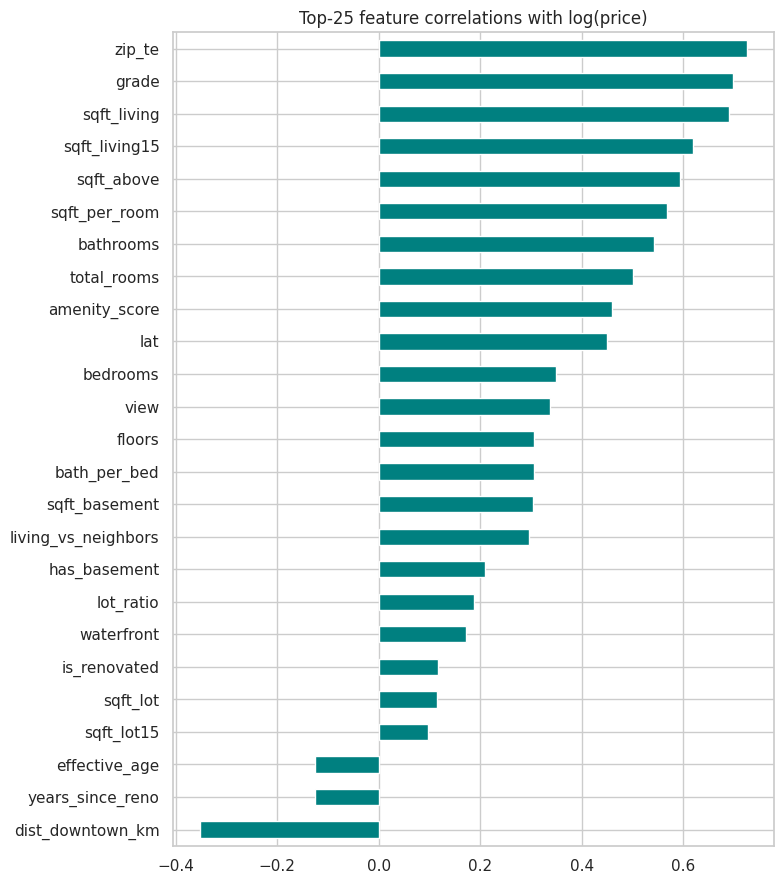

In [ ]:
fe_corr = X_train.assign(log_price=y_train.values).corr()['log_price'].drop('log_price').sort_values(key=abs, ascending=False)
plt.figure(figsize=(8, 9))
fe_corr.head(25).sort_values().plot(kind='barh', color='teal')
plt.title('Top-25 feature correlations with log(price)'); plt.tight_layout(); plt.show()

## 6. Evaluation helpers

In [ ]:
def evaluate(model, X, y_log, name='model'):
    pred_log = model.predict(X)
    pred, true = np.expm1(pred_log), np.expm1(y_log)
    return {
        'Model': name,
        'RMSE (log)': np.sqrt(mean_squared_error(y_log, pred_log)),
        'R2 (log)': r2_score(y_log, pred_log),
        'RMSE ($)': np.sqrt(mean_squared_error(true, pred)),
        'MAE ($)': mean_absolute_error(true, pred),
        'MAPE (%)': np.mean(np.abs(true - pred) / true) * 100,
        'R2 ($)': r2_score(true, pred),
    }

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(model, X, y):
    s = cross_val_score(model, X, y, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    return -s.mean(), s.std()

## 7. Benchmark: baselines vs Gradient Boosting (GBR) vs XGBoost

In [ ]:
models = {
    'Ridge (baseline)': make_pipeline(RobustScaler(), Ridge(alpha=1.0)),
    'Random Forest': RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting (GBR)': GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                                                         subsample=0.8, random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=5, subsample=0.8,
                            colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE),
}

rows, fitted = [], {}
for name, m in models.items():
    cv_m, cv_s = cv_rmse(m, X_train, y_train)
    m.fit(X_train, y_train)
    fitted[name] = m
    r = evaluate(m, X_test, y_test, name)
    r['CV RMSE (log)'] = cv_m
    rows.append(r)
    print(f'{name:28s} CV RMSE(log)={cv_m:.4f} +/- {cv_s:.4f} | Test R2($)={r["R2 ($)"]:.4f}')

bench = pd.DataFrame(rows).set_index('Model').round(4)
bench

Ridge (baseline)             CV RMSE(log)=0.1909 +/- 0.0025 | Test R2($)=0.8571
Random Forest                CV RMSE(log)=0.1743 +/- 0.0019 | Test R2($)=0.8587
Gradient Boosting (GBR)      CV RMSE(log)=0.1625 +/- 0.0020 | Test R2($)=0.8991
XGBoost                      CV RMSE(log)=0.1605 +/- 0.0018 | Test R2($)=0.9082


,RMSE (log),R2 (log),RMSE ($),MAE ($),MAPE (%),R2 ($),CV RMSE (log)
Model,,,,,,,
Ridge (baseline),0.1907,0.8739,145197.0087,82570.8050,14.5511,0.8571,0.1909
Random Forest,0.1733,0.8958,144383.8469,70455.5799,12.4521,0.8587,0.1743
Gradient Boosting (GBR),0.1566,0.9149,122016.0459,63026.8441,11.4045,0.8991,0.1625
XGBoost,0.1550,0.9167,116392.4908,62085.3543,11.2216,0.9082,0.1605


## 8. Hyper-parameter tuning (RandomizedSearchCV)

In [ ]:
xgb_space = {
    'n_estimators': [400, 600, 900, 1200],
    'learning_rate': [0.01, 0.02, 0.03, 0.05, 0.08],
    'max_depth': [3, 4, 5, 6, 7],
    'min_child_weight': [1, 3, 5, 7],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9],
    'reg_alpha': [0, 0.01, 0.1, 1],
    'reg_lambda': [0.5, 1, 2, 5],
}
xgb_search = RandomizedSearchCV(XGBRegressor(n_jobs=-1, random_state=RANDOM_STATE), xgb_space,
                                n_iter=20, cv=3, scoring='neg_root_mean_squared_error',
                                random_state=RANDOM_STATE, n_jobs=1, verbose=1)
xgb_search.fit(X_train, y_train)
print('Best XGB params:', xgb_search.best_params_, '| CV RMSE(log):', -xgb_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best XGB params: {'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha': 0.01, 'n_estimators': 900, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8} | CV RMSE(log): 0.1610334921513775


In [ ]:
gbr_space = {
    'n_estimators': [300, 500, 800, 1000],
    'learning_rate': [0.02, 0.03, 0.05, 0.08],
    'max_depth': [3, 4, 5, 6],
    'min_samples_leaf': [1, 3, 5, 10],
    'subsample': [0.7, 0.8, 0.9],
    'max_features': [None, 0.7, 0.5],
}
gbr_search = RandomizedSearchCV(GradientBoostingRegressor(random_state=RANDOM_STATE), gbr_space,
                                n_iter=12, cv=3, scoring='neg_root_mean_squared_error',
                                random_state=RANDOM_STATE, n_jobs=-1, verbose=1)
gbr_search.fit(X_train, y_train)
print('Best GBR params:', gbr_search.best_params_, '| CV RMSE(log):', -gbr_search.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best GBR params: {'subsample': 0.8, 'n_estimators': 1000, 'min_samples_leaf': 5, 'max_features': None, 'max_depth': 6, 'learning_rate': 0.02} | CV RMSE(log): 0.16144429476466568


## 9. Final comparison on the held-out test set

,RMSE (log),R2 (log),RMSE ($),MAE ($),MAPE (%),R2 ($)
Model,,,,,,
XGBoost,0.1550,0.9167,116392.4908,62085.3543,11.2216,0.9082
Gradient Boosting (GBR) - tuned,0.1565,0.9150,120914.9607,62433.7839,11.2790,0.9009
XGBoost - tuned,0.1557,0.9159,121275.0761,61795.8660,11.1623,0.9003
Gradient Boosting (GBR),0.1566,0.9149,122016.0459,63026.8441,11.4045,0.8991
Random Forest,0.1733,0.8958,144383.8469,70455.5799,12.4521,0.8587
Ridge (baseline),0.1907,0.8739,145197.0087,82570.8050,14.5511,0.8571


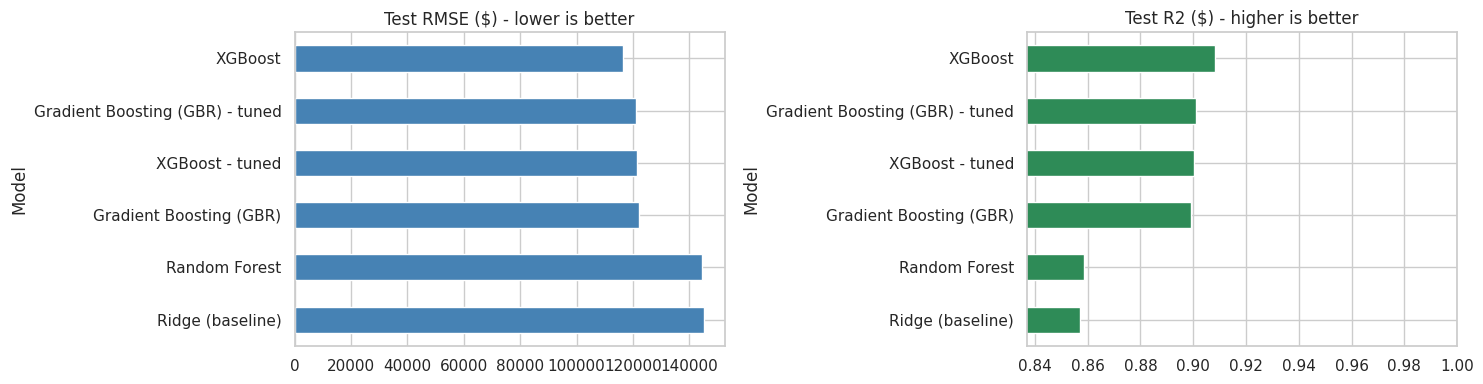

Best model: XGBoost


In [ ]:
fitted['Gradient Boosting (GBR) - tuned'] = gbr_search.best_estimator_
fitted['XGBoost - tuned'] = xgb_search.best_estimator_

final = pd.DataFrame([evaluate(m, X_test, y_test, n) for n, m in fitted.items()]).set_index('Model').round(4)
final = final.sort_values('RMSE ($)')
display(final)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
final['RMSE ($)'].sort_values(ascending=False).plot(kind='barh', ax=ax[0], color='steelblue'); ax[0].set_title('Test RMSE ($) - lower is better')
final['R2 ($)'].sort_values().plot(kind='barh', ax=ax[1], color='seagreen'); ax[1].set_title('Test R2 ($) - higher is better')
ax[1].set_xlim(final['R2 ($)'].min() - 0.02, 1)
plt.tight_layout(); plt.show()

best_name = final.index[0]
best_model = fitted[best_name]
print('Best model:', best_name)

## 10. Diagnostics of the best model

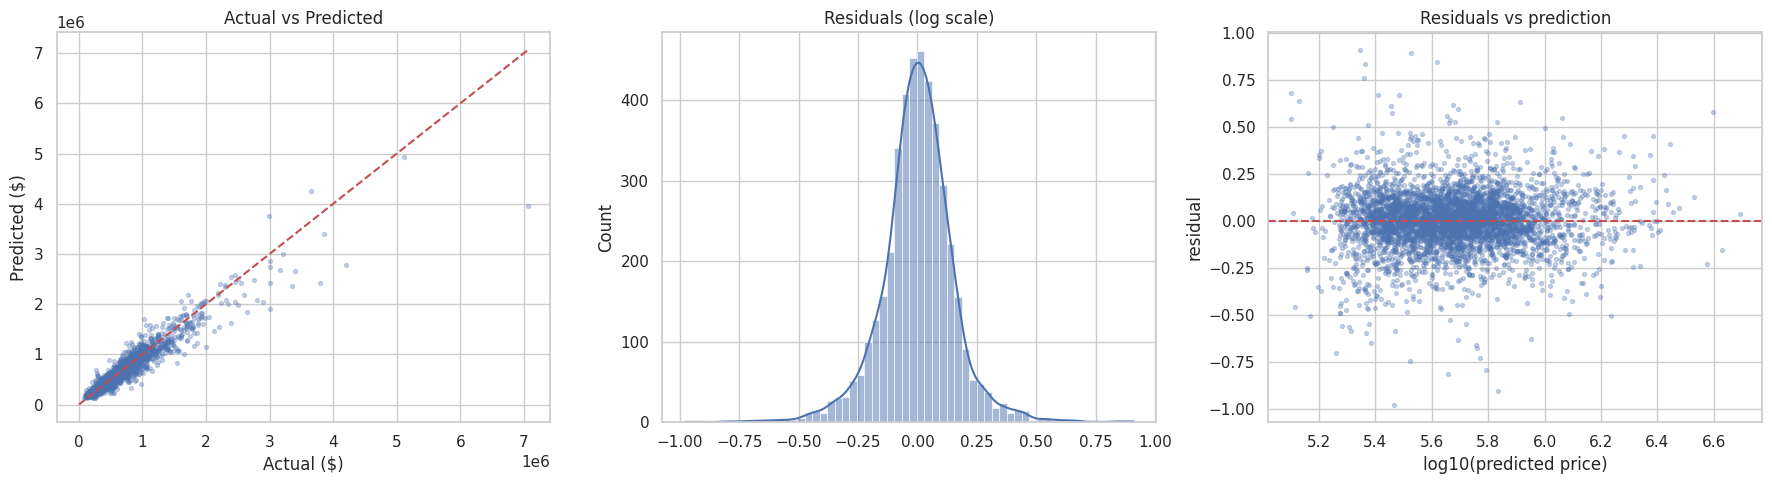

Predictions within 10% of actual price: 59.7%
Predictions within 20% of actual price: 85.4%


In [ ]:
pred = np.expm1(best_model.predict(X_test)); true = np.expm1(y_test)
resid_log = y_test.values - best_model.predict(X_test)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(true, pred, alpha=.3, s=8)
lim = [0, max(true.max(), pred.max())]
ax[0].plot(lim, lim, 'r--'); ax[0].set_xlabel('Actual ($)'); ax[0].set_ylabel('Predicted ($)'); ax[0].set_title('Actual vs Predicted')
sns.histplot(resid_log, bins=60, kde=True, ax=ax[1]); ax[1].set_title('Residuals (log scale)')
ax[2].scatter(np.log10(pred), resid_log, alpha=.3, s=8); ax[2].axhline(0, color='r', ls='--')
ax[2].set_xlabel('log10(predicted price)'); ax[2].set_ylabel('residual'); ax[2].set_title('Residuals vs prediction')
plt.tight_layout(); plt.show()

within10 = np.mean(np.abs(true - pred) / true <= 0.10) * 100
within20 = np.mean(np.abs(true - pred) / true <= 0.20) * 100
print(f'Predictions within 10% of actual price: {within10:.1f}%')
print(f'Predictions within 20% of actual price: {within20:.1f}%')

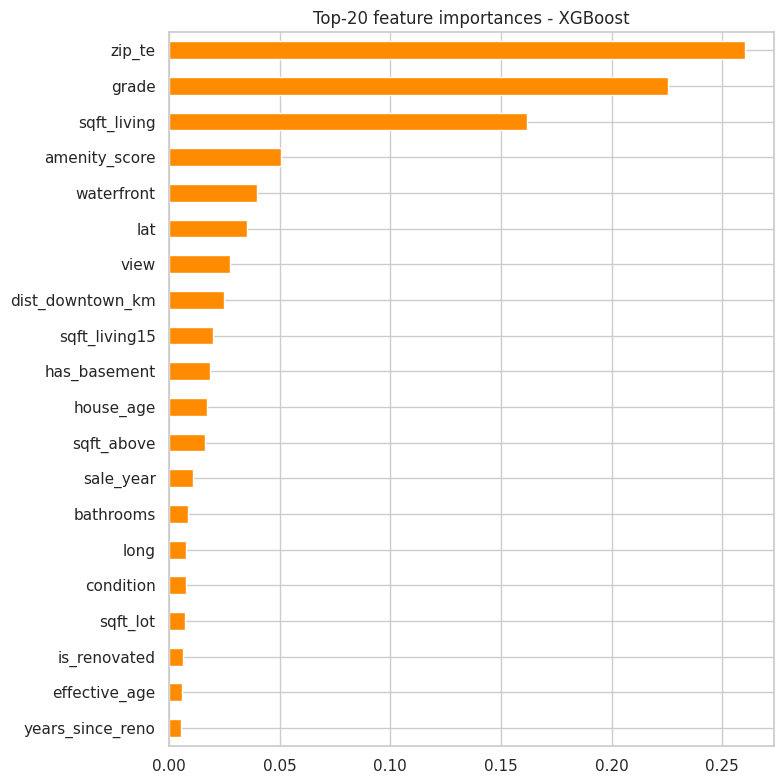

,0
zip_te,0.2604
grade,0.2254
sqft_living,0.1618
amenity_score,0.0507
waterfront,0.0400
lat,0.0355
view,0.0276
dist_downtown_km,0.0247
sqft_living15,0.0199
has_basement,0.0186


In [ ]:
est = best_model
imp = pd.Series(est.feature_importances_, index=FEATURES).sort_values(ascending=False)
plt.figure(figsize=(8, 8))
imp.head(20).sort_values().plot(kind='barh', color='darkorange')
plt.title(f'Top-20 feature importances - {best_name}'); plt.tight_layout(); plt.show()
imp.head(15).round(4)

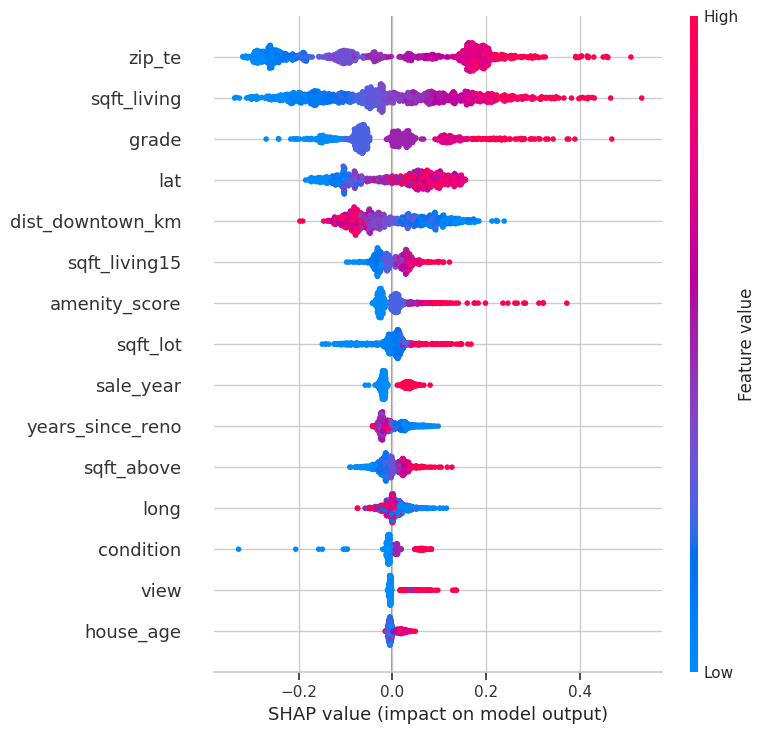

In [ ]:
# Optional: SHAP explanation (works in Colab; skipped silently if shap is not installed)
try:
    import shap
    sample = X_test.sample(1000, random_state=RANDOM_STATE)
    explainer = shap.TreeExplainer(best_model)
    shap.summary_plot(explainer.shap_values(sample), sample, max_display=15)
except Exception as e:
    print('SHAP skipped:', e, '(install with !pip install shap)')

In [ ]:
# Error by price segment & by zip code
res = pd.DataFrame({'zipcode': test_raw['zipcode'], 'true': true.values, 'pred': pred})
res['ape'] = np.abs(res['true'] - res['pred']) / res['true'] * 100
res['segment'] = pd.qcut(res['true'], 5, labels=['Q1 cheapest', 'Q2', 'Q3', 'Q4', 'Q5 priciest'])
print(res.groupby('segment')['ape'].mean().round(2).rename('MAPE %'))
print('\nHardest zip codes (min 20 sales):')
z = res.groupby('zipcode')['ape'].agg(['mean', 'count']); print(z[z['count'] >= 20].sort_values('mean', ascending=False).head(5).round(2))

## 11. Save the model & predict a new house

The saved bundle contains the model and every preprocessing artefact (winsor bounds, zip-code encoder), so new data goes through exactly the same pipeline.

In [ ]:
bundle = {'model': best_model, 'features': FEATURES, 'art': art, 'name': best_name}
joblib.dump(bundle, 'house_price_model.joblib')
print('Saved house_price_model.joblib')

def predict_price(house: dict, bundle=bundle):
    # Predict the sale price (USD) for one house given as a dict of raw columns.
    raw = pd.DataFrame([house])
    X = transform(raw, bundle['art'])[bundle['features']]
    return float(np.expm1(bundle['model'].predict(X))[0])

example = {
    'id': 0, 'date': '20150601T000000', 'price': 0, 'bedrooms': 3, 'bathrooms': 2.0, 'sqft_living': 1800,
    'sqft_lot': 5000, 'floors': 1.0, 'waterfront': 0, 'view': 0, 'condition': 3, 'grade': 7,
    'sqft_above': 1800, 'sqft_basement': 0, 'yr_built': 1990, 'yr_renovated': 0, 'zipcode': 98115,
    'lat': 47.68, 'long': -122.30, 'sqft_living15': 1700, 'sqft_lot15': 5000,
}
print(f'Estimated price: ${predict_price(example):,.0f}')

# Same house, waterfront with a great view
example_wf = {**example, 'waterfront': 1, 'view': 4}
print(f'With waterfront + view 4: ${predict_price(example_wf):,.0f}')

## 12. Conclusions

* **Log-transforming** the target fixed the strong right skew and improved the fit.
* **Outlier handling** (invalid records, IQR on log-price, winsorized features) was learned on the train set only - no leakage.
* **Most influential drivers:** living area, grade, location (zip-code encoding, latitude, distance to downtown), view/waterfront and property age.
* **Boosting models (GBR / XGBoost) clearly outperform** the linear baseline and generally Random Forest; see the table in Section 9 for exact numbers on this run.
* **Business use:** the saved model can power an automated valuation tool; buyers can compare asking prices with predicted fair value.

**Possible improvements:** LightGBM / CatBoost, stacking, external data (school ratings, crime, interest rates), time-aware validation.